## Задание 1. Кластеризация исполнителей по жанрам

В этом задании необходимо кластеризовать исполнителей по жанрам на основе данных о прослушивании.

В файле music_listening.csv по строкам стоят пользователи, а по столбцам - исполнители.

Для каждой пары (пользователь,исполнитель) в таблице стоит число - доля (процент) прослушивания этого исполнителя выбранным пользователем.

In [1]:
import pandas as pd

ratings = pd.read_csv('data/music_listening.csv', low_memory=False)
ratings.head()

,user,the beatles,radiohead,deathcab for cutie,coldplay,modest mouse,sufjan stevens,dylan. bob,red hot clili peppers,pink fluid,...,municipal waste,townes van zandt,curtis mayfield,jewel,lamb,michal w. smith,群星,agalloch,meshuggah,yellowcard
0,0,NaN,0.020417,NaN,NaN,NaN,NaN,NaN,0.030496,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,NaN,0.184962,0.024561,NaN,NaN,0.136341,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,NaN,NaN,0.028635,NaN,NaN,NaN,0.024559,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,0.043529,0.086281,0.034590,0.016712,0.015935,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
ratings = ratings.T
ratings.head()

,0,1,2,3,4,5,6,7,8,9,...,4990,4991,4992,4993,4994,4995,4996,4997,4998,4999
user,0,1,2,3,4,5,6,7,8,9,...,4990,4991,4992,4993,4994,4995,4996,4997,4998,4999
the beatles,NaN,NaN,NaN,NaN,0.043529,NaN,NaN,NaN,0.093398,0.017621,...,NaN,NaN,0.121169,0.038168,0.007939,0.017884,NaN,0.076923,NaN,NaN
radiohead,0.020417,0.184962,NaN,NaN,0.086281,0.006322,NaN,NaN,NaN,0.019156,...,0.017735,NaN,NaN,NaN,0.011187,NaN,NaN,NaN,NaN,NaN
deathcab for cutie,NaN,0.024561,0.028635,NaN,0.03459,NaN,NaN,NaN,NaN,0.013349,...,0.121344,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.027893
coldplay,NaN,NaN,NaN,NaN,0.016712,NaN,NaN,NaN,NaN,NaN,...,0.217175,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Удалите строку под названием user.

In [3]:
ratings = ratings.drop(['user'], axis=0)

Сколько строк осталось в матрице ratings?

In [4]:
ratings.shape[0]

1000

Заполните пропуски нулями.

In [5]:
ratings = ratings.fillna(0)

Нормализуйте данные при помощи normalize.

In [6]:
from sklearn.preprocessing import normalize

index_ = ratings.index
ratings = ratings.replace(',', '.', regex=True).astype('float64')

ratings = pd.DataFrame(normalize(ratings, norm='l2'), index=index_)
ratings.head()

,0,1,2,3,4,5,6,7,8,9,...,4990,4991,4992,4993,4994,4995,4996,4997,4998,4999
the beatles,0.000000,0.000000,0.000000,0.0,0.012054,0.000000,0.0,0.0,0.025864,0.004880,...,0.000000,0.0,0.033554,0.010569,0.002199,0.004952,0.0,0.021302,0.0,0.000000
radiohead,0.009348,0.084688,0.000000,0.0,0.039505,0.002894,0.0,0.0,0.000000,0.008771,...,0.008120,0.0,0.000000,0.000000,0.005122,0.000000,0.0,0.000000,0.0,0.000000
deathcab for cutie,0.000000,0.017278,0.020144,0.0,0.024333,0.000000,0.0,0.0,0.000000,0.009391,...,0.085361,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.019622
coldplay,0.000000,0.000000,0.000000,0.0,0.011129,0.000000,0.0,0.0,0.000000,0.000000,...,0.144628,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000
modest mouse,0.000000,0.000000,0.000000,0.0,0.010260,0.000000,0.0,0.0,0.000000,0.019597,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000


Примените KMeans с 5ю кластерами на преобразованной матрице.

In [7]:
from sklearn.cluster import KMeans

kmenas = KMeans(n_clusters=5)
kmenas.fit(ratings)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",None
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 5000

Выведите на экран центры кластеров (центроиды)

In [8]:
centers = kmenas.cluster_centers_
centers

array([[ 5.90269747e-04,  1.47786779e-03,  0.00000000e+00, ...,
        -2.16840434e-19,  4.49844238e-03,  7.04409808e-04],
       [ 2.89222267e-03,  4.33680869e-19,  1.09763459e-03, ...,
         1.49379696e-03,  1.47646590e-04,  1.25457079e-03],
       [-2.16840434e-19,  1.27153136e-03,  2.27334695e-03, ...,
         2.66175503e-05,  3.11454148e-03,  2.67572236e-04],
       [ 7.95825705e-04,  1.68365410e-03,  4.98063711e-03, ...,
         1.30195135e-03,  3.09235731e-03,  7.22797872e-03],
       [ 1.77102162e-03,  1.32162698e-03,  6.06773030e-04, ...,
         2.60111696e-03,  5.90744082e-04,  9.50106162e-04]],
      shape=(5, 5000))

Для каждого кластера найдем топ-10 исполнителей, наиболее близких к центроидам соотвествующего кластера.

Схожесть исполнителей будем считать по косинусной мере (spatial.distance.cosine).

Вычислите расстояние между "the beatles" и "coldplay". Ответ округлите до сотых.

In [9]:
from scipy import spatial

distanse = spatial.distance.cosine(ratings.loc['the beatles'], ratings.loc['coldplay'])
distanse.round(2)

np.float64(0.9)

Ниже приведена функция, принимающая на вход:

    np.array points - все точки кластера
    pt - центроид кластера
    K = 10 - число Функция возвращает K индексов объектов (строк в массиве points), ближайших к центроид

Примените функцию pClosest (или придумайте свой подход) и выведите для каждого кластера названия топ-10 исполнителей, ближайших к центроиду.

In [10]:
def pClosest(points, pt, K=10):
    ind = [i[0] for i in sorted(enumerate(points), key=lambda x: spatial.distance.cosine(x[1], pt))]
    return ind[:K]

In [11]:
ratings['cluster'] = kmenas.predict(ratings)
cluster_dict = {name: group for name, group in ratings.groupby('cluster')}

In [12]:
for k, v in cluster_dict.items():
    cluster_points = v.drop(columns='cluster')
    closest = pClosest(points=cluster_points.to_numpy(), pt=centers[k], K=10)
    print(cluster_points.index[closest].tolist())

['as i lay dying', 'killswitch engage', 'all that remains', 'metallica', 'underoath', 'chiodos', 'norma jean', 'mudvayne', 'koЯn', 'system of a down']
['fall out boy', 'paramore', 'the all-americian rejects', 'cartel', 'dashboard confesssional', 'the red jumpsuit apparatus', 'kelly clarkson', 'taking back sunday', 'the academy is...', 'the fray']
['descendents', 'against me!', 'rancid', 'the ramones', 'jawbreaker', 'alkaline trio', 'big d and the kids table', 'nofx', 'less than jake', 'streetlight manifesto']
['sufjan stevens', 'the arcade fire', 'the shins', 'radiohead', 'broken social scene', 'belle and sebastian', 'deathcab for cutie', 'andrew bird', 'ironand wine', 'of montreal']
['the beatles', 'the rolling stones', 'led zeppelin.', 'dylan. bob', 'a tribe called quest', 'pink fluid', 'red hot clili peppers', '￼beastie boys', "the roots featuring d'angelo", 'nas']


## Задание 2. Сравнение алгоритмов кластеризации

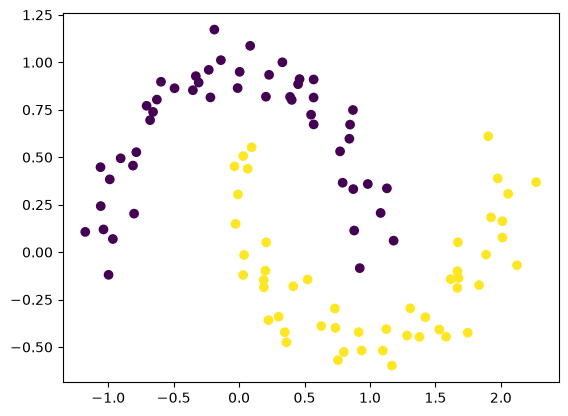

In [13]:
from matplotlib import pyplot as plt
from sklearn.datasets import make_moons
from sklearn.metrics import accuracy_score, silhouette_score, make_scorer
from sklearn.model_selection import GridSearchCV

data = make_moons(n_samples=100, noise=0.1, random_state=42)

X = data[0]
y = data[1]

plt.scatter(X[:,0], X[:,1], c=y)

### KMeans

Попробуйте найти кластеры при помощи KMeans

In [14]:
from sklearn.cluster import KMeans

kmeanss = KMeans(n_clusters=2)
kmeanss.fit(X)
accuracy_score(kmeanss.labels_, y)

0.75

### DBSCAN

Подберите ε и min_samples в DBSCAN, чтобы наилучшим образом найти кластеры. Ищите гиперпараметры из диапазонов:

    eps in [0.05, 0.1, 0.2, 0.28, 0.3, 0.32]
    min_samples in [4, 5, 6, 7]


In [15]:
from sklearn.cluster import DBSCAN

param_grid_dbscan = {
    'eps' : [0.05, 0.1, 0.2, 0.28, 0.3, 0.32],
    'min_samples' : [4, 5, 6, 7]
}

gs_dbscan = GridSearchCV(DBSCAN(), param_grid_dbscan, scoring=make_scorer(silhouette_score))
gs_dbscan.fit(X)
gs_dbscan.best_params_ #eps = 0.05, min_samples=4

/Users/iaroslav/Desktop/ml_course/.venv/lib/python3.13/site-packages/sklearn/model_selection/_validation.py:960: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/Users/iaroslav/Desktop/ml_course/.venv/lib/python3.13/site-packages/sklearn/model_selection/_validation.py", line 947, in _score
    scores = scorer(estimator, X_test, **score_params)
  File "/Users/iaroslav/Desktop/ml_course/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py", line 80, in inner_f
    return f(*args, **kwargs)
TypeError: _BaseScorer.__call__() missing 1 required positional argument: 'y_true'

  warnings.warn(
/Users/iaroslav/Desktop/ml_course/.venv/lib/python3.13/site-packages/sklearn/model_selection/_validation.py:960: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/Users/

{'eps': 0.05, 'min_samples': 4}

In [16]:
import numpy as np
dbscan = DBSCAN(eps=0.28)
dbscan.fit(X)
labels_ = np.where(dbscan.labels_ == 1, 0, 1)
accuracy_score(labels_, y)

1.0

### Иерархическая кластеризация

Используйте иерархическую кластеризацию для поиска кластеров. Задайте в методе 2 кластера. Подберите гиперпараметр linkage из списка ['ward', 'complete', 'average', 'single'], дающий наилучший результат.

In [17]:
from sklearn.cluster import AgglomerativeClustering

ierarh = AgglomerativeClustering(n_clusters=2, linkage='single')
ierarh.fit(X)
labels_ = np.where(ierarh.labels_ == 1, 0, 1)
accuracy_score(labels_, y)

1.0

### Спектральная кластеризация

Попробуйте найти кластеры при помощи спектральной кластеризации. Задайте 2 кластера, affinity='nearest_neighbors'. Подберите гиперпараметр n_neighbors из диапазона [1,2,...,19], чтобы добиться наилучшего результата.

In [27]:
from sklearn.cluster import SpectralClustering

best_neighbors = 1
max_acc_spec = 0

for i in range(1, 20):
    spectral = SpectralClustering(affinity='nearest_neighbors', n_clusters=2, n_neighbors=i)
    spectral.fit(X)
    
    acc = accuracy_score(spectral.labels_, y)
    if acc > max_acc_spec:
        max_acc_spec = acc
        best_neighbors = i


/Users/iaroslav/Desktop/ml_course/.venv/lib/python3.13/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/Users/iaroslav/Desktop/ml_course/.venv/lib/python3.13/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/Users/iaroslav/Desktop/ml_course/.venv/lib/python3.13/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/Users/iaroslav/Desktop/ml_course/.venv/lib/python3.13/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


In [28]:
spectral = SpectralClustering(affinity='nearest_neighbors', n_clusters=2, n_neighbors=best_neighbors)
spectral.fit(X)
accuracy_score(spectral.labels_, y)

/Users/iaroslav/Desktop/ml_course/.venv/lib/python3.13/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


0.88